In [11]:
import s3fs
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr

In [7]:
def open_lazy(path, fs_):
    return xr.open_dataset(
        fs_.open(path, block_size=2**20, cache_type="readahead"),
        engine="h5netcdf"
    )

## 1. NOBM files: inventory

List what Ian uploaded to 'shared/pcc/nobm/': how many files there are, their names, and their sizes.
Expected: One file per month for 1998-2021 (288 files), matching the Rrs files, with fairly small sizes since only the surface layer should have been kept. 
Gaps, duplicates or odd sizes would show up here first

In [2]:
fs = s3fs.S3FileSystem()
NOBM = "mio-water-entero-data/shared/pcc/nobm"
RRS  = "mio-water-entero-data/shared/pcc/oasim"

nobm         = pd.DataFrame(fs.ls(NOBM, detail=True))[["name", "size"]]
nobm["file"] = nobm["name"].str.split("/").str[-1]
nobm["MB"]   = (nobm["size"] / 1e6).round(1)

print(f"{len(nobm)} objects, {nobm["size"].sum()/1e9:.2f} GB total")
print(nobm["MB"].describe().round(1))
print(nobm[["file", "MB"]].head(15))

288 objects, 70.90 GB total
count    288.0
mean     246.2
std        6.6
min      226.5
25%      242.6
50%      250.7
75%      250.7
max      250.7
Name: MB, dtype: float64
             file     MB
0   nobm199801.nc  250.7
1   nobm199802.nc  226.5
2   nobm199803.nc  250.7
3   nobm199804.nc  242.6
4   nobm199805.nc  250.7
5   nobm199806.nc  242.6
6   nobm199807.nc  250.7
7   nobm199808.nc  250.7
8   nobm199809.nc  242.6
9   nobm199810.nc  250.7
10  nobm199811.nc  242.6
11  nobm199812.nc  250.7
12  nobm199901.nc  250.7
13  nobm199902.nc  226.5
14  nobm199903.nc  250.7


## 2. Rrs inventory and match with NOBM

List the OASIM Rrs files the same way, then pair them with the NOBM files by year and month (YYYYMM)
to confirm that every month exists in both sets. File size is used to estimate the number of days per
file (Rrs is about 135 MB per day, NOBM about 8.09 MB per day), so we can check that both agree on
month lengths, and in particular how they treat leap-year Februaries. This is only an estimate from
file size; the next cells read the actual time coordinates.

In [3]:
rrs = pd.DataFrame(fs.ls(RRS, detail=True))[["name", "size"]]
rrs["file"] = rrs["name"].str.split("/").str[-1]

for df, prefix in [(nobm, "nobm"), (rrs, "rrs")]:
    df["yyyymm"] = df["file"].str.extract(r"(\d{6})")[0]
m = nobm.merge(rrs, on="yyyymm", how="outer", suffixes=("_nobm", "_rrs"), indicator=True)
print(f"Rrs: {len(rrs)} files, {rrs['size'].sum()/1e12:.2f} TB")


Rrs: 288 files, 1.18 TB


In [4]:
#Esimtating days per file from size
RRS_DAY = 135_053_568 # 501 x 234 x 288 x 4 bytes
NOBM_DAY = nobm["size"].min() / 28 # rough per-day size from the smallest (Feb.)
m["days_rrs"]  = (m["size_rrs"] / RRS_DAY).round(2)
m["days_nobm"] = (m["size_nobm"] / NOBM_DAY).round(2)
m["month"]     = m["yyyymm"].str[4:].astype(int)
m["year"]      = m["yyyymm"].str[:4].astype(int)

print("Months where day estimates disagree:")
print(m.loc[(m["days_rrs"].round() != m["days_nobm"].round()), ["yyyymm", "days_rrs", "days_nobm"]])
print("\nFebruaries (leap years: 2000, 2004, 2008, 2012, 2016, 2020):")
m.loc[m["month"] == 2, ["yyyymm", "days_rrs", "days_nobm"]]

Months where day estimates disagree:
Empty DataFrame
Columns: [yyyymm, days_rrs, days_nobm]
Index: []

Februaries (leap years: 2000, 2004, 2008, 2012, 2016, 2020):


,yyyymm,days_rrs,days_nobm
1,199802,28.0,28.0
13,199902,28.0,28.0
25,200002,29.0,29.0
37,200102,28.0,28.0
49,200202,28.0,28.0
61,200302,28.0,28.0
73,200402,29.0,29.0
85,200502,28.0,28.0
97,200602,28.0,28.0
109,200702,28.0,28.0


In [5]:
m["_merge"].value_counts()

_merge
both          288
left_only       0
right_only      0
Name: count, dtype: int64

## 3. Structure of one file from each set (January 1998)

Open `nobm199801.nc` and `rrs199801.nc` lazily, reading only the metadata, with no data download.
Check the dimensions, coordinates, variable names, data types, units and global attributes. This
answers several open questions at once: which ~30 variables NOBM contains, whether the Rrs
wavelength axis is 501 bands (and over what range), whether the files store Rrs or nLw (Susanne's
question), and whether both files use the same lat/lon/time coordinates.

In [9]:
ds_n = open_lazy(f"{NOBM}/nobm199801.nc", fs)
ds_r = open_lazy(f"{RRS}/rrs199801.nc", fs)

for name, ds in [("NOBM", ds_n), ("Rrs", ds_r)]:
    print(f"===== {name} =====")
    print(ds)
    print("\nGlobal attributes: ", ds.attrs, "\n")

===== NOBM =====
<xarray.Dataset> Size: 251MB
Dimensions:    (date: 31, lon: 288, lat: 234, component: 6)
Coordinates:
  * date       (date) datetime64[ns] 248B 1998-01-01 1998-01-02 ... 1998-01-31
  * lon        (lon) float32 1kB 0.0 1.0 2.0 3.0 4.0 ... 284.0 285.0 286.0 287.0
  * lat        (lat) float32 936B 0.0 1.0 2.0 3.0 ... 230.0 231.0 232.0 233.0
  * component  (component) <U3 72B 'dia' 'chl' 'cya' 'coc' 'din' 'pha'
Data variables: (12/20)
    tot        (date, lon, lat) float32 8MB ...
    dtc        (date, lon, lat) float32 8MB ...
    pic        (date, lon, lat) float32 8MB ...
    cdc        (date, lon, lat) float32 8MB ...
    t          (date, lon, lat) float32 8MB ...
    s          (date, lon, lat) float32 8MB ...
    ...         ...
    pp         (date, lon, lat, component) float32 50MB ...
    rnh        (date, lon, lat) float32 8MB ...
    rno        (date, lon, lat) float32 8MB ...
    sil        (date, lon, lat) float32 8MB ...
    zoo        (date, lon, lat) floa

## 4. Variables, units, storage layout, and coordinate agreement

List every variable in both files with its dimensions, units, long name and storage settings (chunk
sizes, compression). Units may settle whether the file holds Rrs or nLw. The storage layout
determines how efficient different read patterns will be later (e.g. full spectra for scattered pixels
vs. full maps for one wavelength). Finally, check that both files share the same dates and grid shape,
since NOBM's lon/lat are only index numbers.

In [10]:
def describe(ds):
    rows = []
    for v in ds.data_vars:
        da, enc = ds[v], ds[v].encoding
        rows.append({
            "var": v,
            "dims": da.dims,
            "units": da.attrs.get("units"),
            "long_name": da.attrs.get("long_name"),
            "chunks": enc.get("chunksizes"),
            "compression": enc.get("compression") or enc.get("zlib"),
            "fill": enc.get("_FillValue"),
        })
    return pd.DataFrame(rows)

pd.set_option("display.max_colwidth", 60)
display(describe(ds_n))
display(describe(ds_r))
print("Rrs variable attributes:", ds_r["rrs"].attrs)

print("\nSame dates:", (ds_n.date.values == ds_r.date.values).all())
print("Same grid shape:", (ds_n.sizes["lon"], ds_n.sizes["lat"]) == (ds_r.sizes["lon"], ds_r.sizes["lat"]))
print("Rrs lat spacing:", float(ds_r.lat.diff("lat").mean()), "| lon spacing:", float(ds_r.lon.diff("lon").mean()))

,var,dims,units,long_name,chunks,compression,fill
0,tot,"(date, lon, lat)",None,None,None,False,NaN
1,dtc,"(date, lon, lat)",None,None,None,False,NaN
2,pic,"(date, lon, lat)",None,None,None,False,NaN
3,cdc,"(date, lon, lat)",None,None,None,False,NaN
4,t,"(date, lon, lat)",None,None,None,False,NaN
5,s,"(date, lon, lat)",None,None,None,False,NaN
6,alk,"(date, lon, lat)",None,None,None,False,NaN
7,dic,"(date, lon, lat)",None,None,None,False,NaN
8,doc,"(date, lon, lat)",None,None,None,False,NaN
9,fco,"(date, lon, lat)",None,None,None,False,NaN


,var,dims,units,long_name,chunks,compression,fill
0,rrs,"(date, lon, lat, wavelength)",None,None,None,False,NaN


Rrs variable attributes: {}

Same dates: True
Same grid shape: True
Rrs lat spacing: 0.6641025543212891 | lon spacing: 1.25


## 5. Do NOBM grid cells line up with Rrs grid cells? (land-mask test)

NOBM's lon/lat are only index numbers, so we test whether NOBM cell (i, j) is the same location as
Rrs cell (i, j) by comparing where values are missing (land) on one day. If the masks match, the
grids align and we can copy Rrs's coordinates onto NOBM. A good match only after flipping latitude
would mean NOBM's latitude runs north to south. Maps of temperature, total chlorophyll and Rrs(443)
give a visual check (continents in the right place, warm tropics, chlorophyll-rich upwelling zones).
One full day of Rrs (~135 MB) is read in a single pass, because the file layout makes this faster
than reading one wavelength.

t       missing cells:  26695 of 67392
tot     missing cells:  26695 of 67392
rrs443  missing cells:  26695 of 67392
t vs Rrs mismatched cells (as is):       0
t vs Rrs mismatched cells (lat flipped): 27298
t vs tot mismatched cells:               0


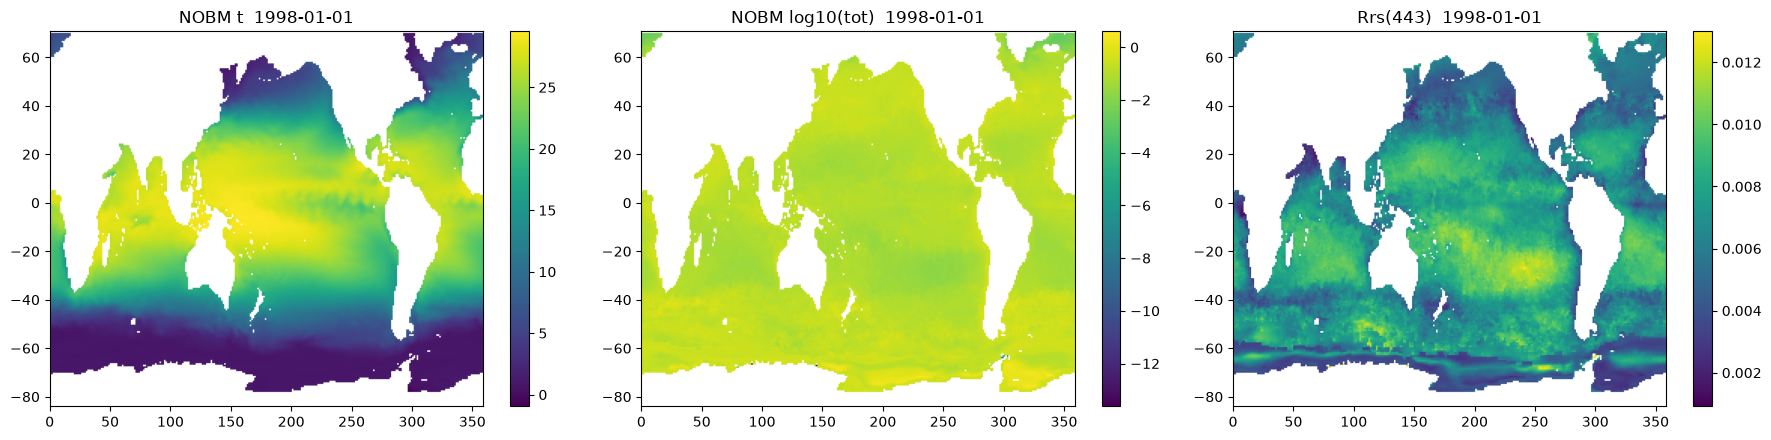

In [12]:
day = 0
t    = ds_n["t"].isel(date=day).load()
tot  = ds_n["tot"].isel(date=day).load()
rday = ds_r["rrs"].isel(date=day).load()          # one day, all wavelengths
r443 = rday.sel(wavelength=443)

m_t, m_tot, m_r = t.isnull().values, tot.isnull().values, r443.isnull().values

for k, m in [("t", m_t), ("tot", m_tot), ("rrs443", m_r)]:
    print(f"{k:7s} missing cells: {m.sum():6d} of {m.size}")
print("t vs Rrs mismatched cells (as is):      ", int((m_t != m_r).sum()))
print("t vs Rrs mismatched cells (lat flipped):", int((m_t[:, ::-1] != m_r).sum()))
print("t vs tot mismatched cells:              ", int((m_t != m_tot).sum()))

ext = [float(ds_r.lon.min()), float(ds_r.lon.max()), float(ds_r.lat.min()), float(ds_r.lat.max())]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (title, arr) in zip(axes, [("NOBM t", t.values),
                                   ("NOBM log10(tot)", np.log10(tot.values)),
                                   ("Rrs(443)", r443.values)]):
    im = ax.imshow(arr.T, origin="lower", extent=ext, aspect="auto")   # arrays are (lon, lat)
    ax.set_title(f"{title}  {str(ds_r.date.values[day])[:10]}")
    fig.colorbar(im, ax=ax)
plt.tight_layout()

## 6. NOBM value sanity check (one month)

Load all of January 1998 (~250 MB) and summarise every variable over ocean cells: minimum, 1st and
99th percentiles, maximum, and the count of negative values. Errors in decoding a binary file
typically show up as absurd numbers (~1e38, huge negatives, temperatures far outside -2…35 °C) or
as a variable that is all zeros or constant. Also test whether `tot` equals the sum of the six groups
in `phy`, which checks both the decoding and what `tot` means.

In [13]:
nb = ds_n.load()                     # whole month, ~250 MB
ocean = ~nb["t"].isnull()            # (date, lon, lat)

rows = []
for v in nb.data_vars:
    da = nb[v]
    if "component" in da.dims:
        for c in da.component.values:
            rows.append((f"{v}[{c}]", da.sel(component=c).where(ocean)))
    else:
        rows.append((v, da.where(ocean)))

stats = []
for name, da in rows:
    x = da.values[np.isfinite(da.values)]
    stats.append({"var": name, "n": x.size,
                  "min": x.min(), "p01": np.percentile(x, 1), "median": np.median(x),
                  "p99": np.percentile(x, 99), "max": x.max(),
                  "n_neg": int((x < 0).sum()), "n_zero": int((x == 0).sum())})
pd.set_option("display.float_format", "{:.4g}".format)
display(pd.DataFrame(stats).set_index("var"))

# does tot equal the sum of the six groups?
phy_sum = nb["phy"].sum("component").where(ocean)
diff = (nb["tot"].where(ocean) - phy_sum)
rel = (diff / nb["tot"].where(ocean)).values
rel = rel[np.isfinite(rel)]
print("tot - sum(phy): max abs diff =", float(np.nanmax(np.abs(diff.values))),
      "| median relative diff =", float(np.median(rel)))

,n,min,p01,median,p99,max,n_neg,n_zero
var,,,,,,,,
tot,1261607,2.36e-14,0.01588,0.13,0.8166,4.655,0,0
dtc,1261607,1.387e-12,0.6297,3.281,18.34,86.98,0,0
pic,1261607,2.223e-15,0.1602,0.8973,7.772,66.48,0,0
cdc,1261607,4.737e-15,0.4904,2.376,9.92,73.42,0,0
t,1261607,-0.9895,0.655,18.98,29.16,29.75,511,0
s,1261607,32.19,32.66,34.55,36.81,37.22,0,0
alk,1261607,2108,2339,2360,2415,2430,0,0
dic,1261607,1814,1956,2074,2213,2267,0,0
doc,1261607,1.952,7.484,22.09,50.76,155.3,0,0


tot - sum(phy): max abs diff = 0.0 | median relative diff = 0.0


## 7. Continuity across a month boundary, and Rrs spectra

(a) A misaligned record in the binary decoding would show up as a jump between files. Compare the
change from 31 January to 1 February with typical day-to-day changes inside January, for `t`, `tot`
and Rrs(443). A boundary jump much larger than the usual daily change would point to a problem.

(b) Plot Rrs spectra (340–750 nm) for a few contrasting ocean pixels: clear subtropical gyre,
high-chlorophyll, and Phaeocystis-dominated. Rrs-shaped spectra (blue peak in clear water,
flattening and a green shift as chlorophyll rises, near zero in the red) would confirm that the
files contain Rrs and not nLw.

t    typical daily change 0.02079 | Jan31->Feb1 0.01714
tot  typical daily change 0.007259 | Jan31->Feb1 0.007663
rrs443 Jan30->Jan31 0.0002897 | Jan31->Feb1 0.0002666


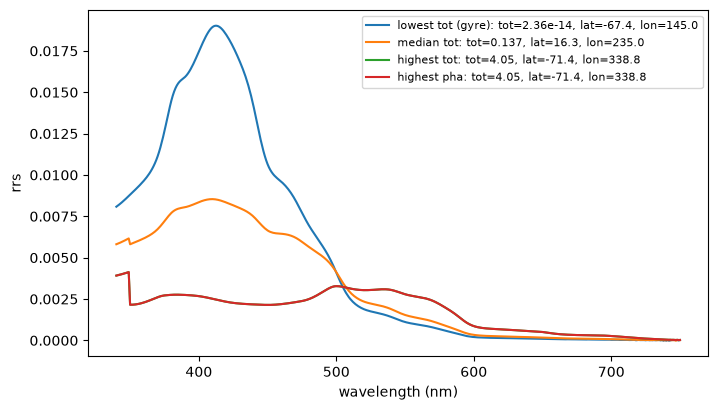

In [14]:
# (a) continuity across the Jan/Feb file boundary
ds_n2 = open_lazy(f"{NOBM}/nobm199802.nc", fs)
ds_r2 = open_lazy(f"{RRS}/rrs199802.nc", fs)

def daily_step(a, b):        # median absolute change over ocean cells
    d = np.abs(b - a)
    return float(np.nanmedian(d))

for v in ["t", "tot"]:
    jan = nb[v].values
    inside = np.median([daily_step(jan[k], jan[k + 1]) for k in range(jan.shape[0] - 1)])
    boundary = daily_step(jan[-1], ds_n2[v].isel(date=0).values)
    print(f"{v:4s} typical daily change {inside:.4g} | Jan31->Feb1 {boundary:.4g}")

r_jan31 = ds_r["rrs"].isel(date=-1).sel(wavelength=443).values
r_jan30 = ds_r["rrs"].isel(date=-2).sel(wavelength=443).values
r_feb1  = ds_r2["rrs"].isel(date=0).sel(wavelength=443).values
print(f"rrs443 Jan30->Jan31 {daily_step(r_jan30, r_jan31):.4g} | Jan31->Feb1 {daily_step(r_jan31, r_feb1):.4g}")

# (b) spectra for contrasting pixels on day 0
tot0, pha0 = nb["tot"].isel(date=0), nb["phy"].sel(component="pha").isel(date=0)
picks = {
    "lowest tot (gyre)": np.unravel_index(np.nanargmin(tot0.values), tot0.shape),
    "median tot":        np.unravel_index(np.nanargmin(np.abs(tot0.values - np.nanmedian(tot0.values))), tot0.shape),
    "highest tot":       np.unravel_index(np.nanargmax(tot0.values), tot0.shape),
    "highest pha":       np.unravel_index(np.nanargmax(pha0.values), pha0.shape),
}
wl = slice(340, 750)
fig, ax = plt.subplots(figsize=(8, 4.5))
for label, (i, j) in picks.items():
    spec = rday.isel(lon=i, lat=j).sel(wavelength=wl)
    ax.plot(spec.wavelength, spec,
            label=f"{label}: tot={float(tot0[i, j]):.3g}, lat={float(ds_r.lat[j]):.1f}, lon={float(ds_r.lon[i]):.1f}")
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("rrs"); ax.legend(fontsize=8)